# 08 — Learned Policy Visualization

Trains each method for 500 episodes (single seed per method-env pair)
and visualizes the greedy policy as arrows on top of a V(s) heatmap.


In [1]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----
# Set N_RUNS=50 for pilot, bump to 500 for final overnight run
N_RUNS = 50
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}

SEED = 42
N_EP_VIZ = 500


In [2]:
Qs = {env_name: {} for env_name in ENVS}
for env_name, env_fn in ENVS.items():
    for m_name, (fn, kw) in METHODS.items():
        env = env_fn(seed=SEED) if 'seed' in env_fn.__code__.co_varnames else env_fn()
        Q, _ = fn(env, N_EP_VIZ, alpha=ALPHA_DEFAULT, eps=EPS_DEFAULT, seed=SEED, **kw)
        Qs[env_name][m_name] = Q
print('trained')


trained


In [3]:
def plot_policy(ax, Q, env_fn, title=''):
    env = env_fn()
    rows, cols = env.rows, env.cols
    V = Q.max(axis=1).reshape(rows, cols)
    greedy_a = Q.argmax(axis=1).reshape(rows, cols)

    # mask cliff cells for V display
    cliff_mask = np.zeros((rows, cols), dtype=bool)
    for r, c in env.cliff:
        cliff_mask[r, c] = True
    V_masked = np.where(cliff_mask, np.nan, V)

    im = ax.imshow(V_masked, cmap='viridis', aspect='equal',
                   vmin=-100, vmax=0)

    from envs import UP, RIGHT, DOWN, LEFT
    arrow_dx = {UP: 0, RIGHT: 0.3, DOWN: 0, LEFT: -0.3}
    arrow_dy = {UP: -0.3, RIGHT: 0, DOWN: 0.3, LEFT: 0}

    for r in range(rows):
        for c in range(cols):
            if (r, c) == env.start or (r, c) == env.goal:
                continue
            if (r, c) in env.cliff:
                continue
            a = greedy_a[r, c]
            ax.arrow(c, r, arrow_dx[a], arrow_dy[a], head_width=0.2, head_length=0.14,
                     fc='white', ec='white', linewidth=0.7)

    # shade cliff cells
    for (r, c) in env.cliff:
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1,
                                    facecolor='#882222', alpha=0.7, zorder=2))

    ax.text(env.start[1], env.start[0], 'S', ha='center', va='center',
            color='yellow', fontsize=9, fontweight='bold', zorder=3)
    ax.text(env.goal[1], env.goal[0], 'G', ha='center', va='center',
            color='yellow', fontsize=9, fontweight='bold', zorder=3)
    ax.set_title(title, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    return im


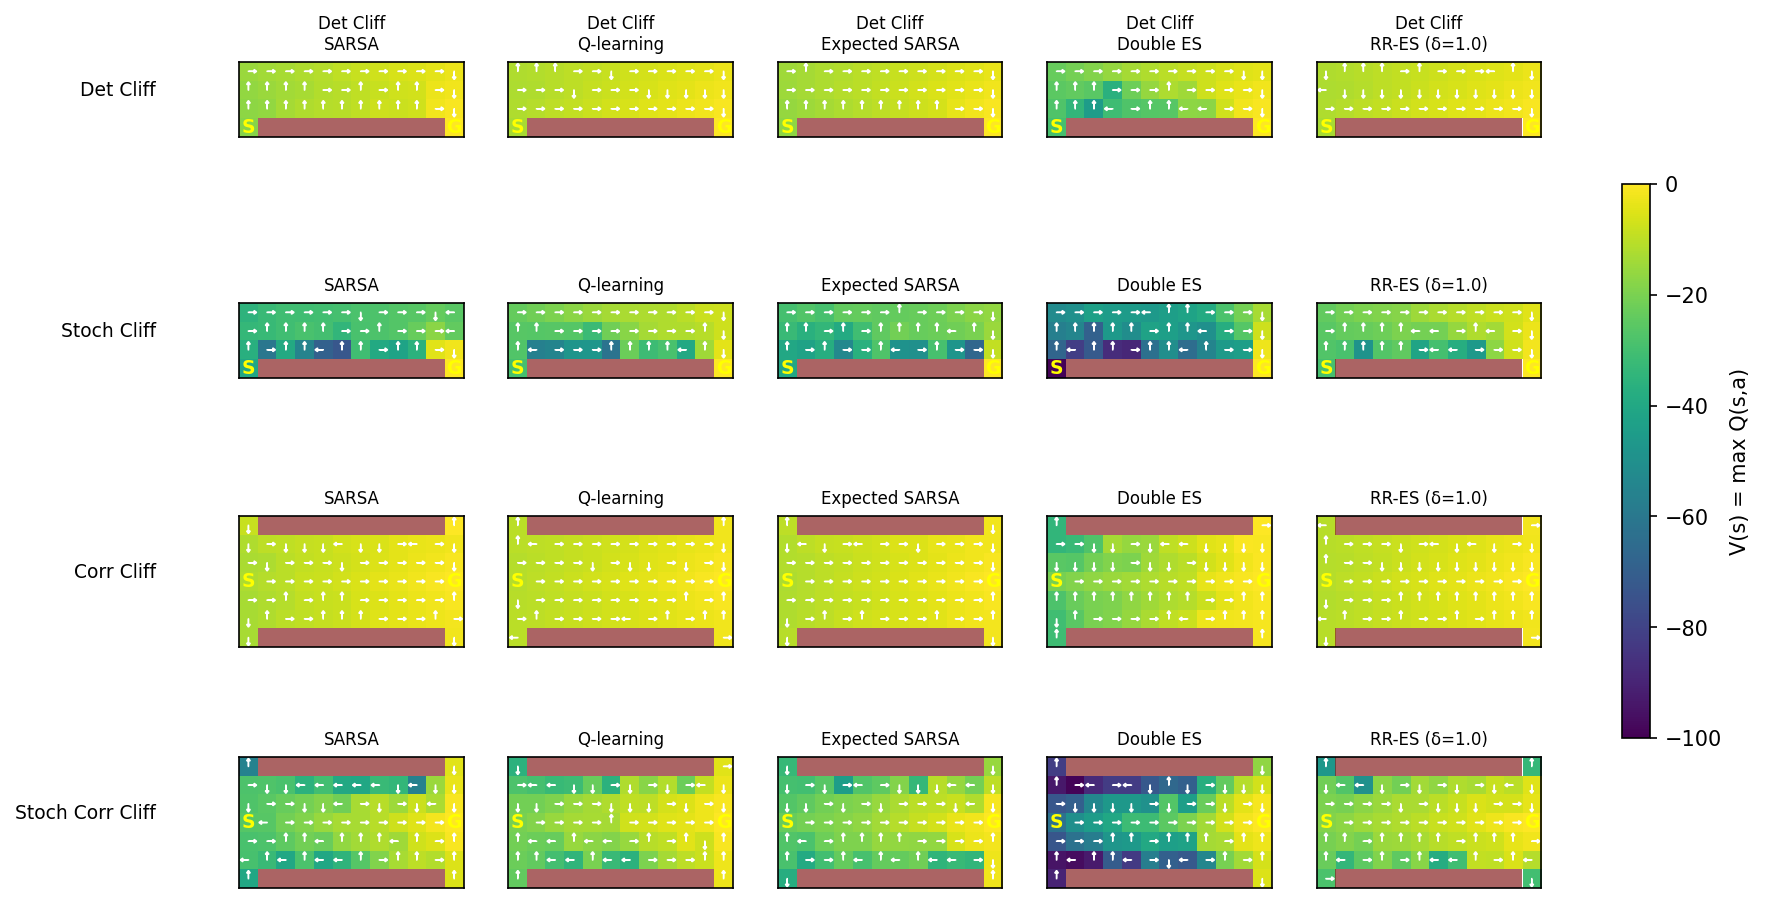

In [4]:
# One big grid: 4 envs (rows) x 5 methods (cols)
fig, axes = plt.subplots(len(ENVS), len(METHODS), figsize=(14, 8), dpi=150)
for r, (env_name, env_fn) in enumerate(ENVS.items()):
    for c, m_name in enumerate(METHODS):
        ax = axes[r, c]
        im = plot_policy(ax, Qs[env_name][m_name], env_fn,
                         title=f'{env_name}\n{m_name}' if r == 0 else m_name)
        if c == 0:
            ax.set_ylabel(env_name, fontsize=9, rotation=0, labelpad=40, ha='right')
fig.colorbar(im, ax=axes, shrink=0.6, label='V(s) = max Q(s,a)')
plt.savefig('../results/figures/08_policy_viz_grid.png', dpi=200, bbox_inches='tight')
plt.show()


In [5]:
import numpy as np
import sys
sys.path.insert(0, '..')
from utils import pairwise_table

# ===== CELL 1: full-100 vs last-30 comparison =====
d02 = np.load('../results/data/02_main_comparison.npz')

print("Keys in nb 02 data:")
for k in d02.files:
    print(f"  {k}")

print()
print("=" * 70)
print("Per-method full-100-eps mean vs last-30 mean, for each env:")
print("=" * 70)

envs = ['Det_Cliff', 'Stoch_Cliff', 'Corr_Cliff', 'Stoch_Corr_Cliff']
for env in envs:
    print(f"\n### {env} ###")
    print(f"  {'method':<30}{'full-100':<12}{'last-30':<12}{'diff':<10}")
    for key in d02.files:
        if key.startswith(env + '__'):
            arr = d02[key]
            full_mean = arr.mean()
            last30_mean = arr[:, -30:].mean()
            diff = full_mean - last30_mean
            method = key[len(env)+2:]
            print(f"  {method:<30}{full_mean:<+12.2f}{last30_mean:<+12.2f}{diff:<+10.2f}")


# ===== CELL 2: re-run pairwise on last-30 metric =====
print("\n\n" + "=" * 70)
print("Pairwise comparisons on LAST-30 episodes (not full-100):")
print("=" * 70)
for env in envs:
    env_data = {}
    for key in d02.files:
        if key.startswith(env + '__'):
            method = key[len(env)+2:]
            env_data[method] = d02[key][:, -30:].mean(axis=1)
    if env_data:
        print(f"\n###### {env} ######")
        pairwise_table(env_data, metric_name=f'last30 on {env}')

Keys in nb 02 data:
  n_runs
  alpha
  eps
  slip
  Det_Cliff__SARSA
  Det_Cliff__Q-learning
  Det_Cliff__Expected_SARSA
  Det_Cliff__Double_ES
  Det_Cliff__RR-ES_delta_1.0
  Stoch_Cliff__SARSA
  Stoch_Cliff__Q-learning
  Stoch_Cliff__Expected_SARSA
  Stoch_Cliff__Double_ES
  Stoch_Cliff__RR-ES_delta_1.0
  Corr_Cliff__SARSA
  Corr_Cliff__Q-learning
  Corr_Cliff__Expected_SARSA
  Corr_Cliff__Double_ES
  Corr_Cliff__RR-ES_delta_1.0
  Stoch_Corr_Cliff__SARSA
  Stoch_Corr_Cliff__Q-learning
  Stoch_Corr_Cliff__Expected_SARSA
  Stoch_Corr_Cliff__Double_ES
  Stoch_Corr_Cliff__RR-ES_delta_1.0

Per-method full-100-eps mean vs last-30 mean, for each env:

### Det_Cliff ###
  method                        full-100    last-30     diff      
  SARSA                         -83.63      -33.15      -50.48    
  Q-learning                    -91.84      -44.60      -47.24    
  Expected_SARSA                -73.53      -25.07      -48.46    
  Double_ES                     -111.34     -60.36      -50.

In [1]:
import numpy as np
d = np.load('../results/data/02_main_comparison.npz')
envs = ['Det_Cliff', 'Stoch_Cliff', 'Corr_Cliff', 'Stoch_Corr_Cliff']
for env in envs:
    print(f"\n### {env} ###")
    print(f"  {'method':<30}{'last-30 mean':<15}{'SEM':<10}")
    for key in d.files:
        if key.startswith(env + '__'):
            arr = d[key]
            last30_per_run = arr[:, -30:].mean(axis=1)
            m = last30_per_run.mean()
            s = last30_per_run.std(ddof=1) / np.sqrt(len(last30_per_run))
            method = key[len(env)+2:]
            print(f"  {method:<30}{m:<+15.2f}{s:<+10.2f}")


### Det_Cliff ###
  method                        last-30 mean   SEM       
  SARSA                         -33.34         +0.34     
  Q-learning                    -46.89         +0.52     
  Expected_SARSA                -26.16         +0.21     
  Double_ES                     -55.41         +0.76     
  RR-ES_delta_1.0               -48.24         +0.54     

### Stoch_Cliff ###
  method                        last-30 mean   SEM       
  SARSA                         -101.32        +1.99     
  Q-learning                    -87.92         +1.52     
  Expected_SARSA                -87.26         +1.52     
  Double_ES                     -121.81        +2.06     
  RR-ES_delta_1.0               -87.59         +1.60     

### Corr_Cliff ###
  method                        last-30 mean   SEM       
  SARSA                         -27.25         +0.28     
  Q-learning                    -41.50         +0.35     
  Expected_SARSA                -26.47         +0.21     
  Double_ES 